# Credit Scoring: Prediksi Default Nasabah Kartu Kredit
**UTS Finansial Teknologi** | Universitas Siber Indonesia | Kelas 13.5A.23
**Kelompok:**
- Muhammad Adnan Azwan (13240018)
- Mohammad Panji Satrio (13240019)
- Cecilia Putri Winarno (13240021)
- Rendy Aditya Rahmat (13240015)

**Metodologi:** CRISP-DM

## Daftar Isi
1. Business Understanding
2. Data Understanding
3. Data Preparation
4. Modeling
5. Evaluation
6. Deployment
7. Kesimpulan

## Sumber & Catatan
- **Dataset:** Default of Credit Card Clients, UCI Machine Learning Repository (Yeh & Lien, 2009)
- **Referensi:** Yeh, I. C., & Lien, C. H. (2009). The comparisons of data mining techniques for the predictive accuracy of probability of default of credit card clients. *Expert Systems with Applications, 36*(2), 2473–2480.

In [1]:
# @title
!pip -q install ucimlrepo xgboost shap gradio

In [2]:
# @title
# ============ 0. SETUP ============
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

os.makedirs("figures", exist_ok=True)
os.makedirs("models", exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 1. Business Understanding

**Latar belakang.** Pada layanan pinjaman (termasuk P2P lending), kegagalan bayar (default) adalah risiko utama. Credit scoring membantu platform menilai kelayakan peminjam sebelum dana disalurkan.

**Tujuan bisnis.** Mengurangi kerugian akibat default dengan mengidentifikasi nasabah berisiko tinggi lebih awal.

**Tujuan data mining.** Membangun model klasifikasi biner untuk memprediksi apakah nasabah akan default pada bulan berikutnya (`default = 1`).

**Biaya kesalahan.**
- *False Negative* (nasabah berisiko diprediksi aman): kerugian pokok pinjaman → **lebih mahal**
- *False Positive* (nasabah baik ditolak): hilangnya peluang bunga

**Kriteria sukses.** ROC-AUC dan Recall kelas default sebagai metrik utama, didukung Precision, F1, PR-AUC, dan KS statistic. Accuracy tidak dipakai sebagai metrik utama karena data tidak seimbang.

## 2. Data Understanding
### 2.1 Memuat Data

In [3]:
# @title
from ucimlrepo import fetch_ucirepo

raw = fetch_ucirepo(id=350)  # Default of Credit Card Clients
X, y = raw.data.features.copy(), raw.data.targets.copy()

COLS = (
    ["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE"]
    + [f"PAY_{i}" for i in range(1, 7)]
    + [f"BILL_AMT{i}" for i in range(1, 7)]
    + [f"PAY_AMT{i}" for i in range(1, 7)]
)
assert X.shape[1] == len(COLS) == 23, "Jumlah kolom tidak sesuai"

df = X.copy()
df.columns = COLS
df["default"] = y.iloc[:, 0].values

print("Dimensi data :", df.shape)
df.head()

Dimensi data : (30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


### 2.2 Deskripsi Fitur
| Fitur | Keterangan |
|---|---|
| LIMIT_BAL | Limit kredit (NT$) |
| SEX | 1 = pria, 2 = wanita |
| EDUCATION | 1 = pascasarjana, 2 = universitas, 3 = SMA, 4 = lainnya |
| MARRIAGE | 1 = menikah, 2 = lajang, 3 = lainnya |
| AGE | Usia (tahun) |
| PAY_1 … PAY_6 | Status pembayaran April–September 2005 (-1 = bayar tepat waktu, 1–9 = telat n bulan) |
| BILL_AMT1 … 6 | Tagihan bulanan |
| PAY_AMT1 … 6 | Jumlah pembayaran bulanan |
| **default** | **Target: 1 = gagal bayar bulan depan** |

In [4]:
# @title
# ============ 2.3 KUALITAS DATA ============
print("Tipe data:\n", df.dtypes.value_counts(), "\n")
print("Missing value total :", df.isna().sum().sum())
print("Baris duplikat      :", df.duplicated().sum())

print("\nDistribusi target:")
dist = df["default"].value_counts().to_frame("jumlah")
dist["persen"] = (dist["jumlah"] / len(df) * 100).round(2)
display(dist)

df.describe().T


Tipe data:
 int64    24
Name: count, dtype: int64 

Missing value total : 0
Baris duplikat      : 35

Distribusi target:


,jumlah,persen
default,,
0,23364,77.88
1,6636,22.12


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_1,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0
PAY_5,30000.0,-0.266200,1.133187,-2.0,-1.00,0.0,0.00,8.0


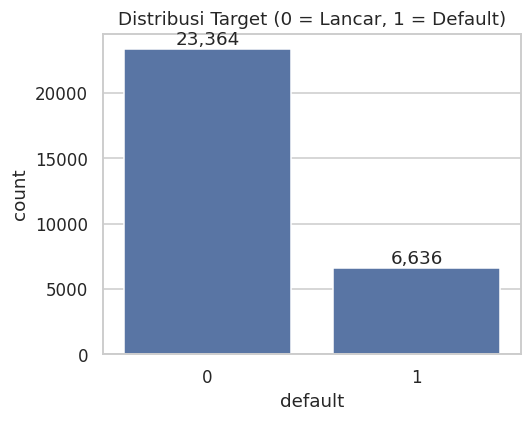

In [5]:
# @title
# ============ 2.4 DISTRIBUSI TARGET ============
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="default", ax=ax)
ax.set_title("Distribusi Target (0 = Lancar, 1 = Default)")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
save_fig("01_target_distribution")

--- SEX ---
SEX
1    11888
2    18112 

--- EDUCATION ---
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51 

--- MARRIAGE ---
MARRIAGE
0       54
1    13659
2    15964
3      323 



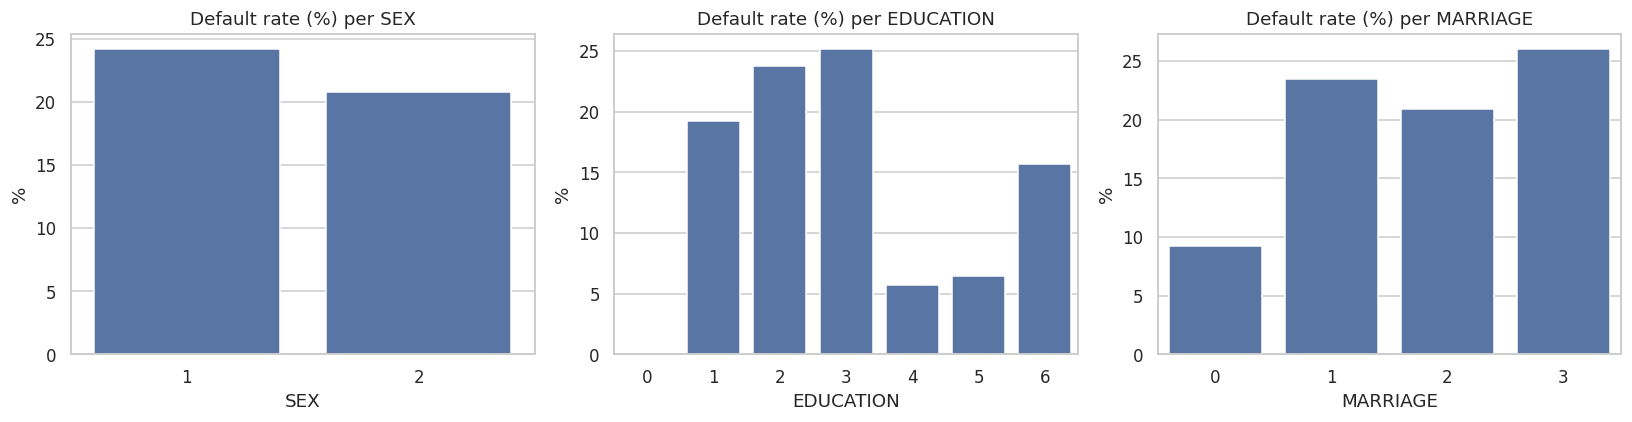

In [6]:
# @title
# ============ 2.5 FITUR KATEGORIKAL ============
cat_cols = ["SEX", "EDUCATION", "MARRIAGE"]

for c in cat_cols:
    print(f"--- {c} ---")
    print(df[c].value_counts().sort_index().to_string(), "\n")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, cat_cols):
    rate = df.groupby(c)["default"].mean().mul(100)
    sns.barplot(x=rate.index, y=rate.values, ax=ax)
    ax.set_title(f"Default rate (%) per {c}")
    ax.set_ylabel("%")
save_fig("02_default_rate_categorical")

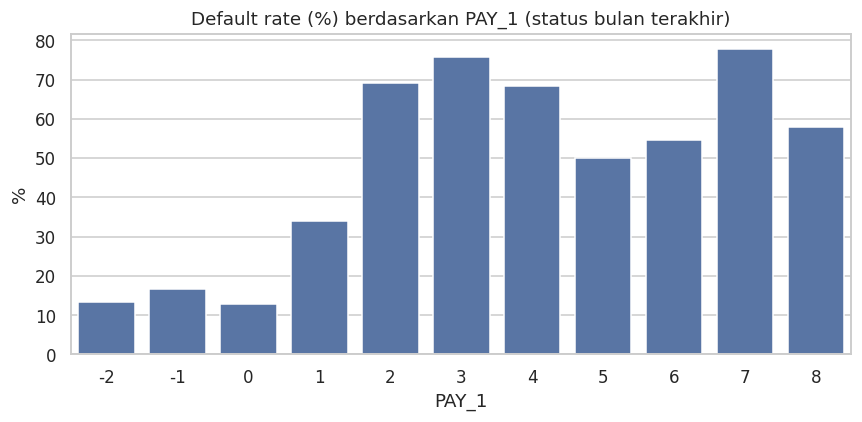

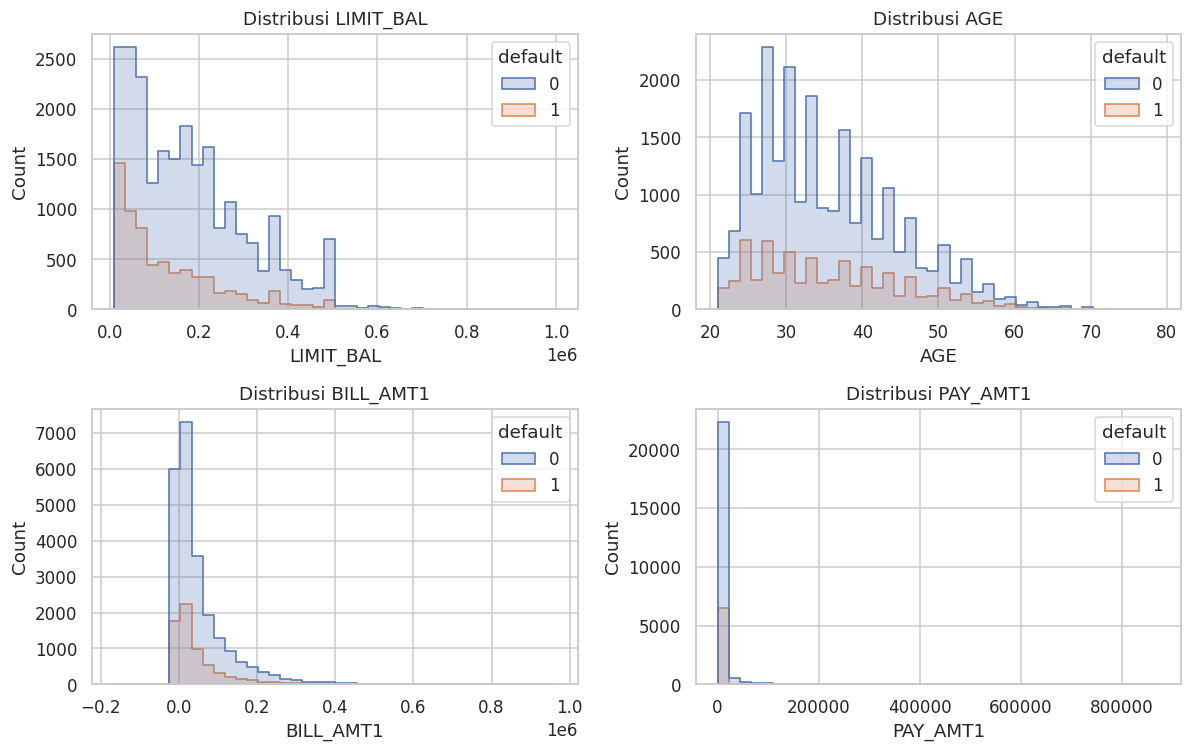

In [7]:
# @title
# ============ 2.6 STATUS PEMBAYARAN (PAY_) ============
fig, ax = plt.subplots(figsize=(8, 4))
rate = df.groupby("PAY_1")["default"].mean().mul(100)
sns.barplot(x=rate.index, y=rate.values, ax=ax)
ax.set_title("Default rate (%) berdasarkan PAY_1 (status bulan terakhir)")
ax.set_ylabel("%")
save_fig("03_default_rate_pay1")

# ============ 2.7 FITUR NUMERIK ============
num_cols = ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(data=df, x=c, hue="default", bins=40, ax=ax, element="step")
    ax.set_title(f"Distribusi {c}")
save_fig("04_numeric_distribution")


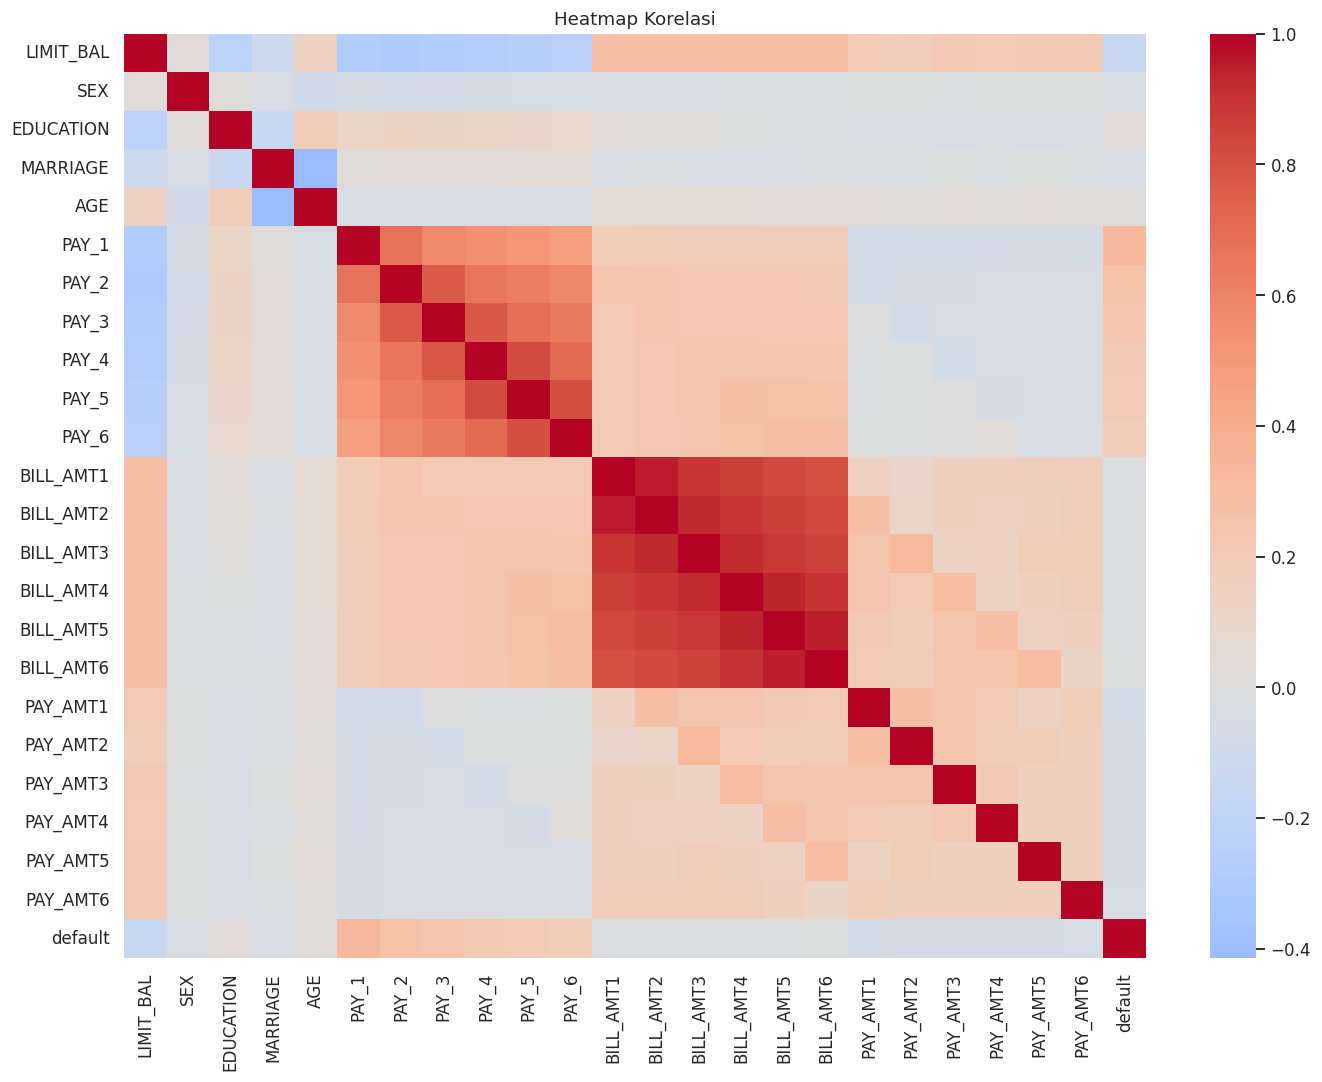

,default
PAY_1,0.324794
PAY_2,0.263551
PAY_3,0.235253
PAY_4,0.216614
PAY_5,0.204149
PAY_6,0.186866
LIMIT_BAL,-0.153520
PAY_AMT1,-0.072929
PAY_AMT2,-0.058579
PAY_AMT4,-0.056827


In [8]:
# @title
# ============ 2.8 KORELASI ============
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(df.corr(), cmap="coolwarm", center=0, ax=ax)
ax.set_title("Heatmap Korelasi")
save_fig("05_correlation_heatmap")

df.corr()["default"].drop("default").sort_values(key=abs, ascending=False).head(10)

### 2.9 Temuan Data Understanding
- Dataset berisi 30.000 nasabah dengan 23 fitur dan 1 target; seluruh fitur bertipe numerik.
- Tidak ada missing value, tetapi terdapat 35 baris duplikat.
- Target tidak seimbang: 77,88% lancar (23.364) vs 22,12% default (6.636).
- Komposisi (sebelum pembersihan): 60,4% wanita; pendidikan universitas 46,8%, pascasarjana 35,3%, SMA 16,4%; status lajang 53,2% dan menikah 45,5%.
- Kategori tidak terdefinisi: EDUCATION bernilai 0, 5, 6 (total 345 baris) dan MARRIAGE bernilai 0 (54 baris), padahal kamus data hanya mendefinisikan 1–4 dan 1–3. Kategori ini digabung ke "lainnya".
- PAY_1–PAY_6 memiliki nilai -2 dan 0 yang tidak didokumentasikan pada sumber dataset; dicatat sebagai keterbatasan.
- BILL_AMT memiliki nilai negatif (kelebihan bayar) dan rentang yang sangat lebar (distribusi miring, banyak outlier), sehingga perlu scaling.
- Fitur paling berkorelasi dengan default adalah status pembayaran (PAY_1 r = 0,325; PAY_2 r = 0,264; PAY_3 r = 0,235), dengan kekuatan yang menurun untuk bulan yang lebih lama (PAY_6 r = 0,187). LIMIT_BAL berkorelasi negatif (r = -0,154), sedangkan PAY_AMT berkorelasi lemah (|r| < 0,08). Korelasi Pearson hanya menunjukkan hubungan linear, bukan sebab-akibat.
- Fitur BILL_AMT1–6 saling berkorelasi tinggi (multikolinearitas), sehingga perlu diperhatikan pada model linear.

## 3. Data Preparation
Langkah: (1) pembersihan data, (2) feature engineering, (3) pembagian data train/test dengan stratifikasi, (4) preprocessing dalam Pipeline agar tidak terjadi data leakage.

In [9]:
# @title
# ============ 3.1 CLEANING ============
df_clean = df.drop_duplicates().reset_index(drop=True)
print(f"Setelah hapus duplikat: {df.shape[0]} -> {df_clean.shape[0]} baris")

df_clean["EDUCATION"] = df_clean["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df_clean["MARRIAGE"] = df_clean["MARRIAGE"].replace({0: 3})

print("\nEDUCATION:", sorted(df_clean["EDUCATION"].unique()))
print("MARRIAGE :", sorted(df_clean["MARRIAGE"].unique()))
print("\nProporsi target:\n", df_clean["default"].value_counts(normalize=True).round(4))

Setelah hapus duplikat: 30000 -> 29965 baris

EDUCATION: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
MARRIAGE : [np.int64(1), np.int64(2), np.int64(3)]

Proporsi target:
 default
0    0.7787
1    0.2213
Name: proportion, dtype: float64


In [10]:
# @title
# ============ 3.2 FEATURE ENGINEERING ============
PAY_COLS  = [f"PAY_{i}" for i in range(1, 7)]
BILL_COLS = [f"BILL_AMT{i}" for i in range(1, 7)]
AMT_COLS  = [f"PAY_AMT{i}" for i in range(1, 7)]

def add_features(d):
    d = d.copy()
    d["PAY_MEAN"]  = d[PAY_COLS].mean(axis=1)                  # rata-rata status bayar
    d["PAY_MAX"]   = d[PAY_COLS].max(axis=1)                   # keterlambatan terparah
    d["N_LATE"]    = (d[PAY_COLS] > 0).sum(axis=1)             # jumlah bulan telat
    d["UTIL_1"]    = d["BILL_AMT1"] / d["LIMIT_BAL"]           # utilisasi limit bulan terakhir
    d["UTIL_MEAN"] = d[BILL_COLS].mean(axis=1) / d["LIMIT_BAL"]
    ratio = d[AMT_COLS].sum(axis=1) / (d[BILL_COLS].clip(lower=0).sum(axis=1) + 1)
    d["PAY_RATIO"] = ratio.clip(0, 5)                          # rasio bayar/tagihan, dibatasi 0-5
    return d

df_fe = add_features(df_clean)
new_feats = ["PAY_MEAN", "PAY_MAX", "N_LATE", "UTIL_1", "UTIL_MEAN", "PAY_RATIO"]
print(df_fe[new_feats + ["default"]].corr()["default"].drop("default").round(3))

PAY_MEAN     0.282
PAY_MAX      0.331
N_LATE       0.398
UTIL_1       0.086
UTIL_MEAN    0.115
PAY_RATIO   -0.078
Name: default, dtype: float64


In [11]:
# @title
# ============ 3.3 SPLIT & PREPROCESSING ============
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

TARGET = "default"
X = df_fe.drop(columns=TARGET)
y = df_fe[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

cat_cols = ["SEX", "EDUCATION", "MARRIAGE"]
num_cols = [c for c in X.columns if c not in cat_cols]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Default rate train: {y_train.mean():.4f} | test: {y_test.mean():.4f}")
print(f"Fitur numerik: {len(num_cols)} | kategorikal: {len(cat_cols)}")

Train: (23972, 29) | Test: (5993, 29)
Default rate train: 0.2213 | test: 0.2213
Fitur numerik: 26 | kategorikal: 3


### 3.4 Ringkasan Data Preparation
- 35 baris duplikat dihapus; kategori tidak terdefinisi pada EDUCATION dan MARRIAGE digabung ke "lainnya".
- Ditambahkan 6 fitur turunan: PAY_MEAN, PAY_MAX, N_LATE, UTIL_1, UTIL_MEAN, PAY_RATIO.
- Dari fitur turunan, N_LATE memiliki korelasi tertinggi dengan default (r = 0,398), lebih tinggi daripada fitur mentah mana pun (PAY_1 r = 0,325 pada data sebelum pembersihan); PAY_MAX r = 0,331 dan PAY_MEAN r = 0,282.
- Data dibagi 80:20 secara stratified (random_state = 42) sehingga proporsi default terjaga.
- Scaling dan encoding dilakukan di dalam Pipeline (fit hanya pada data train) untuk mencegah data leakage.
- Ketidakseimbangan kelas ditangani lewat class weighting pada tahap modeling.

## 4. Modeling
Tiga algoritma dibandingkan dengan Stratified 5-Fold Cross-Validation pada data train:
1. **Logistic Regression**: baseline standar credit scoring, mudah diinterpretasi
2. **Random Forest**: ensemble bagging, menangkap hubungan non-linear
3. **XGBoost**: gradient boosting, umumnya terbaik pada data tabular

Ketidakseimbangan kelas ditangani dengan class weighting (`class_weight` / `scale_pos_weight`).

In [12]:
# @title
# ============ 4.1 DEFINISI MODEL ============
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from xgboost import XGBClassifier

spw = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "Logistic Regression": Pipeline([
        ("prep", preprocessor),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)),
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocessor),
        ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                       class_weight="balanced_subsample",
                                       n_jobs=-1, random_state=SEED)),
    ]),
    "XGBoost": Pipeline([
        ("prep", preprocessor),
        ("clf", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                              subsample=0.8, colsample_bytree=0.8,
                              scale_pos_weight=spw, eval_metric="auc",
                              n_jobs=-1, random_state=SEED)),
    ]),
}

# ============ 4.2 CROSS-VALIDATION ============
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision",
           "recall": "recall", "precision": "precision", "f1": "f1"}

rows = []
for name, pipe in models.items():
    cv = cross_validate(pipe, X_train, y_train, cv=skf, scoring=scoring, n_jobs=1)
    row = {"Model": name}
    for m in scoring:
        row[m] = f"{cv[f'test_{m}'].mean():.4f} ± {cv[f'test_{m}'].std():.4f}"
    rows.append(row)
    print(f"selesai: {name}")

cv_table = pd.DataFrame(rows).set_index("Model")
cv_table.to_csv("figures/cv_results.csv")
cv_table

selesai: Logistic Regression
selesai: Random Forest
selesai: XGBoost


,roc_auc,pr_auc,recall,precision,f1
Model,,,,,
Logistic Regression,0.7596 ± 0.0107,0.5045 ± 0.0178,0.6258 ± 0.0115,0.4530 ± 0.0081,0.5255 ± 0.0088
Random Forest,0.7829 ± 0.0075,0.5550 ± 0.0098,0.5258 ± 0.0127,0.5641 ± 0.0167,0.5442 ± 0.0120
XGBoost,0.7858 ± 0.0089,0.5626 ± 0.0114,0.6356 ± 0.0083,0.4672 ± 0.0103,0.5385 ± 0.0094


In [13]:
# @title
# ============ 4.3 HYPERPARAMETER TUNING (XGBoost) ============
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "clf__n_estimators":     [200, 300, 500],
    "clf__max_depth":        [3, 4, 5, 6],
    "clf__learning_rate":    [0.03, 0.05, 0.1],
    "clf__subsample":        [0.7, 0.8, 1.0],
    "clf__colsample_bytree": [0.6, 0.8, 1.0],
    "clf__min_child_weight": [1, 3, 5],
}

search = RandomizedSearchCV(
    models["XGBoost"], param_dist, n_iter=15, scoring="roc_auc",
    cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
    random_state=SEED, n_jobs=-1, verbose=1,
)
search.fit(X_train, y_train)

print("Best CV ROC-AUC :", round(search.best_score_, 4))
print("Best params     :", search.best_params_)

tuned_xgb = search.best_estimator_

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best CV ROC-AUC : 0.7889
Best params     : {'clf__subsample': 0.8, 'clf__n_estimators': 200, 'clf__min_child_weight': 5, 'clf__max_depth': 4, 'clf__learning_rate': 0.05, 'clf__colsample_bytree': 0.8}


In [14]:
# @title
# ============ 4.4 TRAIN MODEL FINAL ============
final_models = {
    "Logistic Regression": models["Logistic Regression"].fit(X_train, y_train),
    "Random Forest":       models["Random Forest"].fit(X_train, y_train),
    "XGBoost (tuned)":     tuned_xgb,
}
print("Semua model sudah dilatih:", list(final_models))

Semua model sudah dilatih: ['Logistic Regression', 'Random Forest', 'XGBoost (tuned)']


### 4.5 Ringkasan Modeling
- XGBoost memiliki ROC-AUC CV tertinggi (0,7858 ± 0,0089), unggul 0,0262 dari Logistic Regression (0,7596 ± 0,0107) dan 0,0029 dari Random Forest (0,7829 ± 0,0075). Selisih dengan Random Forest lebih kecil daripada standar deviasi antar-fold, sehingga keduanya praktis setara; keunggulan yang jelas hanya terhadap baseline.
- Tuning (RandomizedSearchCV, 15 kandidat, 3-fold) menghasilkan ROC-AUC CV terbaik 0,7889 dengan `n_estimators` = 200, `max_depth` = 4, `learning_rate` = 0,05, `subsample` = 0,8, `colsample_bytree` = 0,8, `min_child_weight` = 5. Kenaikannya hanya 0,0031 dari XGBoost awal (0,7858) dan masih di bawah standar deviasi antar-fold. Skema CV-nya berbeda (3-fold vs 5-fold), jadi angka ini bukan perbandingan langsung.
- Pada Recall CV, XGBoost (0,6356) dan Logistic Regression (0,6258) lebih tinggi daripada Random Forest (0,5258). Random Forest memiliki Precision tertinggi (0,5641) tetapi Recall terendah, kurang sesuai dengan tujuan bisnis karena False Negative lebih mahal.
- Logistic Regression tetap kompetitif: Recall-nya hampir setara XGBoost dan modelnya lebih mudah dijelaskan, meskipun ROC-AUC dan PR-AUC (0,5045 vs 0,5626) lebih rendah.

## 5. Evaluation
Model dievaluasi pada data test (20%) yang tidak pernah dipakai saat training maupun tuning. Metrik: ROC-AUC, PR-AUC, KS statistic, Precision, Recall, F1. Threshold klasifikasi dipilih dari prediksi *out-of-fold* pada data train (bukan data test) untuk menghindari kebocoran informasi.

In [15]:
# @title
# ============ 5.1 METRIK DATA TEST (threshold 0.5) ============
from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score,
    precision_score, f1_score, accuracy_score, confusion_matrix,
    roc_curve, precision_recall_curve, ConfusionMatrixDisplay)

def ks_stat(y_true, p):
    fpr, tpr, _ = roc_curve(y_true, p)
    return np.max(tpr - fpr)

rows, probas = [], {}
for name, m in final_models.items():
    p = m.predict_proba(X_test)[:, 1]
    probas[name] = p
    pred = (p >= 0.5).astype(int)
    rows.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, p),
        "PR-AUC": average_precision_score(y_test, p),
        "KS": ks_stat(y_test, p),
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
results.to_csv("figures/test_results.csv")
results

,ROC-AUC,PR-AUC,KS,Accuracy,Precision,Recall,F1
Model,,,,,,,
Logistic Regression,0.7536,0.5117,0.3990,0.7464,0.4458,0.6018,0.5122
Random Forest,0.7739,0.5535,0.4163,0.8016,0.5565,0.5090,0.5317
XGBoost (tuned),0.7789,0.5642,0.4270,0.7524,0.4568,0.6297,0.5295


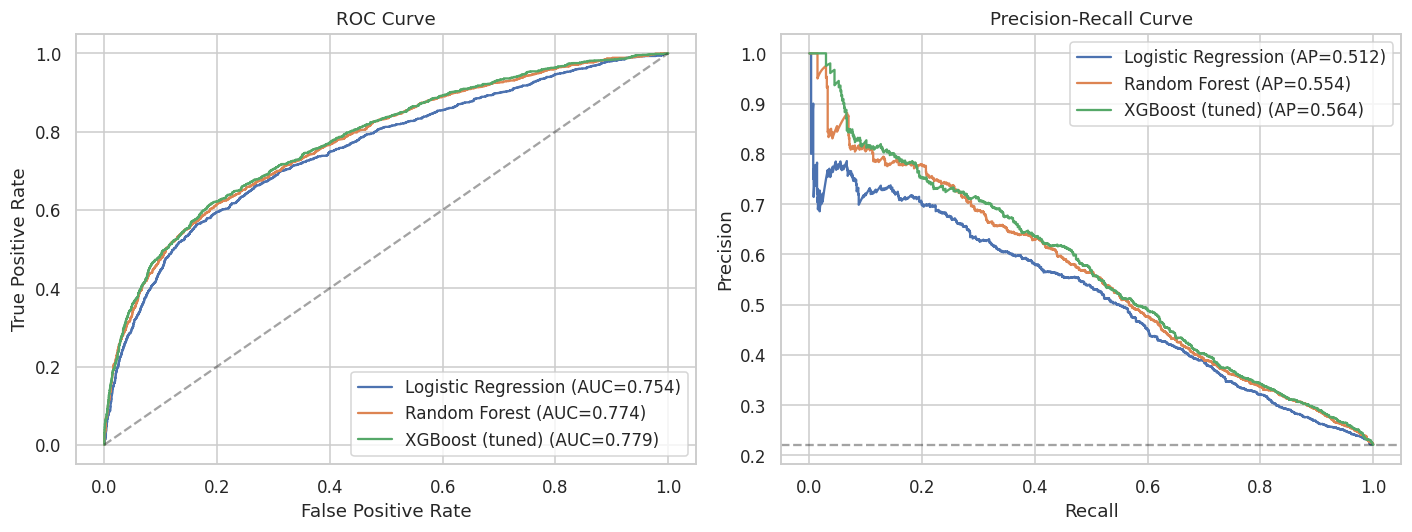

In [16]:
# @title
# ============ 5.2 ROC & PR CURVE ============
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rc, pr, label=f"{name} (AP={average_precision_score(y_test, p):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[0].set(title="ROC Curve", xlabel="False Positive Rate", ylabel="True Positive Rate")
axes[1].axhline(y_test.mean(), color="k", ls="--", alpha=.4)
axes[1].set(title="Precision-Recall Curve", xlabel="Recall", ylabel="Precision")
axes[0].legend(); axes[1].legend()
save_fig("06_roc_pr_curves")

Threshold terpilih (maks F2 di OOF train): 0.332


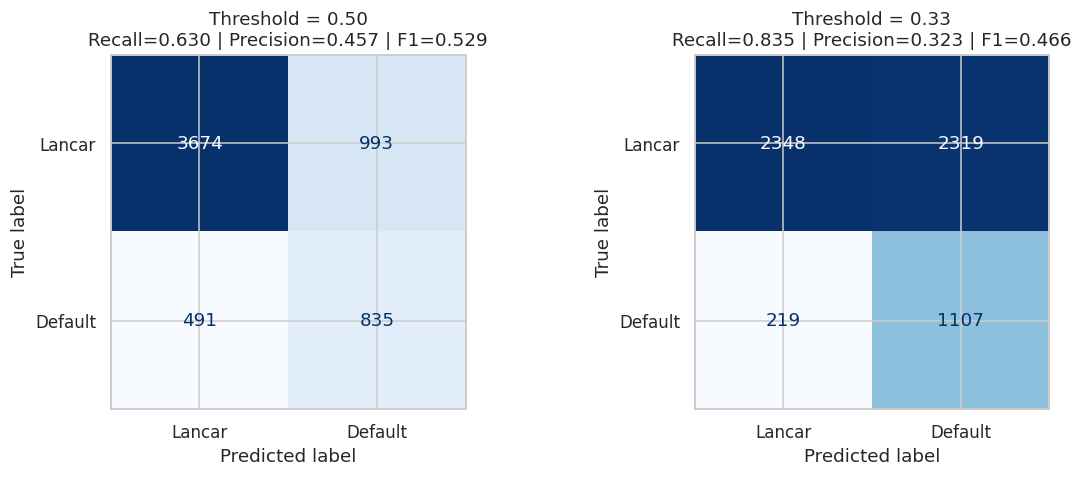

In [17]:
# @title
# ============ 5.3 THRESHOLD TUNING ============
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone

BEST_NAME = "XGBoost (tuned)"   # ganti jika model lain lebih baik di CV
best_model = final_models[BEST_NAME]

# probabilitas out-of-fold di data TRAIN
oof = cross_val_predict(clone(best_model), X_train, y_train, cv=skf,
                        method="predict_proba", n_jobs=1)[:, 1]

# F2-score: recall dibobot 2x precision (biaya False Negative lebih besar)
prec, rec, thr = precision_recall_curve(y_train, oof)
f2 = 5 * prec * rec / (4 * prec + rec + 1e-9)
best_thr = thr[np.argmax(f2[:-1])]
print(f"Threshold terpilih (maks F2 di OOF train): {best_thr:.3f}")

# evaluasi di test: threshold 0.5 vs threshold terpilih
p = probas[BEST_NAME]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, t in zip(axes, [0.5, best_thr]):
    pred = (p >= t).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["Lancar", "Default"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"Threshold = {t:.2f}\nRecall={recall_score(y_test, pred):.3f} | "
                 f"Precision={precision_score(y_test, pred):.3f} | F1={f1_score(y_test, pred):.3f}")
save_fig("07_confusion_matrix")

### 5.4 Kalibrasi Probabilitas
Model dilatih dengan *class weighting* (`scale_pos_weight`) agar kelas default tidak terabaikan. Efek sampingnya, angka `predict_proba` condong **terlalu tinggi** dan tidak bisa dibaca sebagai peluang sebenarnya. Padahal credit scoring butuh peluang gagal bayar (*probability of default*) yang jujur, misalnya untuk menghitung skor, batas risiko, dan kerugian yang diharapkan.

**Metode.** `CalibratedClassifierCV` dengan dua kandidat: *sigmoid* (Platt scaling) dan *isotonic*. Pemilihan metode memakai **Brier score out-of-fold pada data train**, bukan data test, supaya tidak ada kebocoran. Model terkalibrasi lalu dievaluasi di data test.

**Metrik.** Brier score dan Log loss (makin kecil makin baik), ECE (rata-rata selisih peluang prediksi vs proporsi default nyata per kelompok), reliability diagram, dan rata-rata P(default) dibanding proporsi default sebenarnya. Karena skala probabilitas berubah, threshold F2 juga **dihitung ulang** pada skala terkalibrasi.

Brier out-of-fold (train):  {'tanpa kalibrasi': np.float64(0.1764), 'sigmoid': np.float64(0.1333), 'isotonic': np.float64(0.1329)}
Metode kalibrasi terpilih : isotonic

Proporsi default sebenarnya di data test: 0.2213


,Brier,Log loss,ECE,Rata-rata P(default),ROC-AUC
Sebelum kalibrasi,0.1792,0.5411,0.1964,0.4177,0.7789
Sesudah kalibrasi,0.1347,0.4288,0.0143,0.2208,0.7801


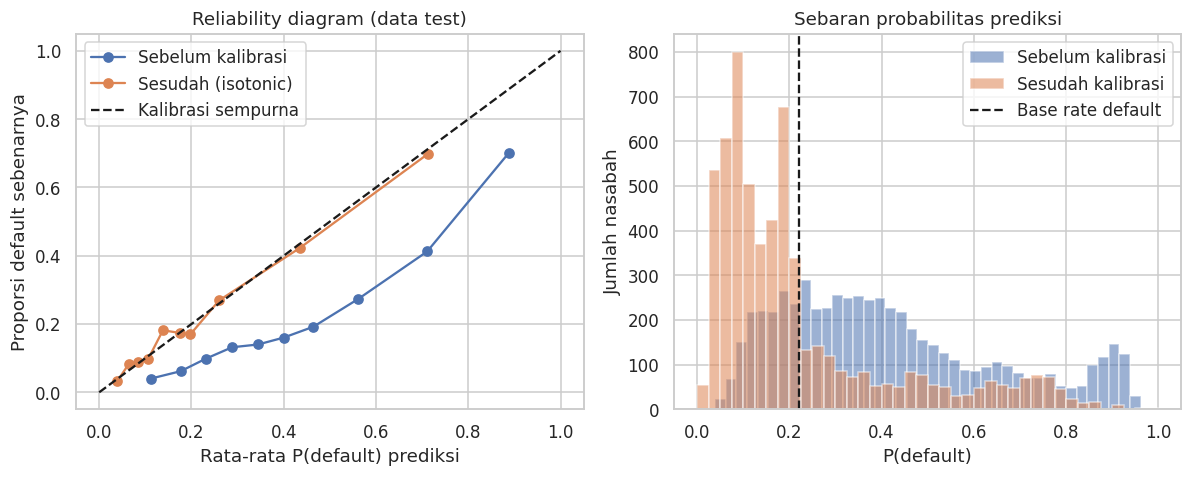

,Threshold,Recall,Precision,F1,FN (default lolos),FP (lancar ditandai)
Sebelum kalibrasi,0.3324,0.8348,0.3231,0.4659,219.0,2319.0
Sesudah kalibrasi,0.1322,0.8379,0.3282,0.4717,215.0,2274.0


**Ringkasan 5.4.** Sebelum kalibrasi, rata-rata P(default) = 0.418 padahal proporsi default sebenarnya 0.221. Sesudah kalibrasi (isotonic), rata-ratanya 0.221. Brier turun dari 0.1792 ke 0.1347, Log loss dari 0.5411 ke 0.4288, ECE dari 0.1964 ke 0.0143. ROC-AUC 0.7789 → 0.7801 (kalibrasi memperbaiki kejujuran angka peluang, bukan kemampuan membedakan). Threshold F2 pada skala terkalibrasi = 0.132 (skala lama: 0.332).

In [18]:
# @title
# ============ 5.4 KALIBRASI PROBABILITAS ============
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss, log_loss
from IPython.display import Markdown, display

def ece_score(y_true, p, n_bins=10):
    """Expected Calibration Error: rata-rata selisih |peluang prediksi - proporsi default nyata| per bin."""
    d = pd.DataFrame({"y": np.asarray(y_true), "p": np.asarray(p)})
    d["bin"] = pd.qcut(d["p"], q=n_bins, duplicates="drop")
    g = d.groupby("bin", observed=True).agg(n=("y", "size"), y=("y", "mean"), p=("p", "mean"))
    return float((g["n"] / g["n"].sum() * (g["y"] - g["p"]).abs()).sum())

def cal_metrics(y_true, p):
    return {"Brier": brier_score_loss(y_true, p), "Log loss": log_loss(y_true, np.clip(p, 1e-6, 1 - 1e-6)),
            "ECE": ece_score(y_true, p), "Rata-rata P(default)": float(np.mean(p)),
            "ROC-AUC": roc_auc_score(y_true, p)}

# 1) Pilih metode kalibrasi memakai data TRAIN saja (out-of-fold), bukan data test
oof_cal = {}
for method in ["sigmoid", "isotonic"]:
    cal = CalibratedClassifierCV(clone(best_model), method=method, cv=3)
    oof_cal[method] = cross_val_predict(cal, X_train, y_train, cv=skf,
                                        method="predict_proba", n_jobs=1)[:, 1]
brier_oof = {m: brier_score_loss(y_train, p) for m, p in oof_cal.items()}
CAL_METHOD = min(brier_oof, key=brier_oof.get)
print("Brier out-of-fold (train): ",
      {"tanpa kalibrasi": round(brier_score_loss(y_train, oof), 4),
       **{k: round(v, 4) for k, v in brier_oof.items()}})
print("Metode kalibrasi terpilih :", CAL_METHOD)

# 2) Latih model terkalibrasi pada seluruh data train, evaluasi di test
calibrated_model = CalibratedClassifierCV(clone(best_model), method=CAL_METHOD, cv=5).fit(X_train, y_train)
p_test_raw = probas[BEST_NAME]
p_test_cal = calibrated_model.predict_proba(X_test)[:, 1]

cmp = pd.DataFrame({"Sebelum kalibrasi": cal_metrics(y_test, p_test_raw),
                    "Sesudah kalibrasi": cal_metrics(y_test, p_test_cal)}).T
cmp["Rata-rata P(default)"] = cmp["Rata-rata P(default)"].round(4)
cmp = cmp.round(4)
cmp.to_csv("figures/calibration_results.csv")
print(f"\nProporsi default sebenarnya di data test: {y_test.mean():.4f}")
display(cmp)

# 3) Reliability diagram
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for lab, pp in [("Sebelum kalibrasi", p_test_raw), (f"Sesudah ({CAL_METHOD})", p_test_cal)]:
    fy, fx = calibration_curve(y_test, pp, n_bins=10, strategy="quantile")
    axes[0].plot(fx, fy, marker="o", label=lab)
axes[0].plot([0, 1], [0, 1], "k--", label="Kalibrasi sempurna")
axes[0].set_xlabel("Rata-rata P(default) prediksi"); axes[0].set_ylabel("Proporsi default sebenarnya")
axes[0].set_title("Reliability diagram (data test)"); axes[0].legend()
axes[1].hist(p_test_raw, bins=40, alpha=.55, label="Sebelum kalibrasi")
axes[1].hist(p_test_cal, bins=40, alpha=.55, label="Sesudah kalibrasi")
axes[1].axvline(y_test.mean(), color="k", ls="--", label="Base rate default")
axes[1].set_xlabel("P(default)"); axes[1].set_ylabel("Jumlah nasabah")
axes[1].set_title("Sebaran probabilitas prediksi"); axes[1].legend()
save_fig("07b_kalibrasi")

# 4) Threshold ulang pada skala probabilitas terkalibrasi (maks F2 di OOF train)
prec_c, rec_c, thr_c = precision_recall_curve(y_train, oof_cal[CAL_METHOD])
f2_c = 5 * prec_c * rec_c / (4 * prec_c + rec_c + 1e-9)
best_thr_cal = float(thr_c[np.argmax(f2_c[:-1])])

def at_thr(p, t):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"Threshold": t, "Recall": recall_score(y_test, pred), "Precision": precision_score(y_test, pred),
            "F1": f1_score(y_test, pred), "FN (default lolos)": fn, "FP (lancar ditandai)": fp}

thr_tbl = pd.DataFrame({
    "Sebelum kalibrasi": at_thr(p_test_raw, best_thr),
    "Sesudah kalibrasi": at_thr(p_test_cal, best_thr_cal),
}).T.round(4)
thr_tbl.to_csv("figures/threshold_calibrated.csv")
display(thr_tbl)

# 5) Ringkasan otomatis (angka diambil langsung dari hasil run di atas)
r, c = cmp.loc["Sebelum kalibrasi"], cmp.loc["Sesudah kalibrasi"]
display(Markdown(
    f"**Ringkasan 5.4.** Sebelum kalibrasi, rata-rata P(default) = {r['Rata-rata P(default)']:.3f} padahal proporsi default sebenarnya "
    f"{y_test.mean():.3f}. Sesudah kalibrasi ({CAL_METHOD}), rata-ratanya {c['Rata-rata P(default)']:.3f}. "
    f"Brier turun dari {r['Brier']:.4f} ke {c['Brier']:.4f}, Log loss dari {r['Log loss']:.4f} ke {c['Log loss']:.4f}, "
    f"ECE dari {r['ECE']:.4f} ke {c['ECE']:.4f}. ROC-AUC {r['ROC-AUC']:.4f} → {c['ROC-AUC']:.4f} "
    f"(kalibrasi memperbaiki kejujuran angka peluang, bukan kemampuan membedakan). "
    f"Threshold F2 pada skala terkalibrasi = {best_thr_cal:.3f} (skala lama: {best_thr:.3f})."))


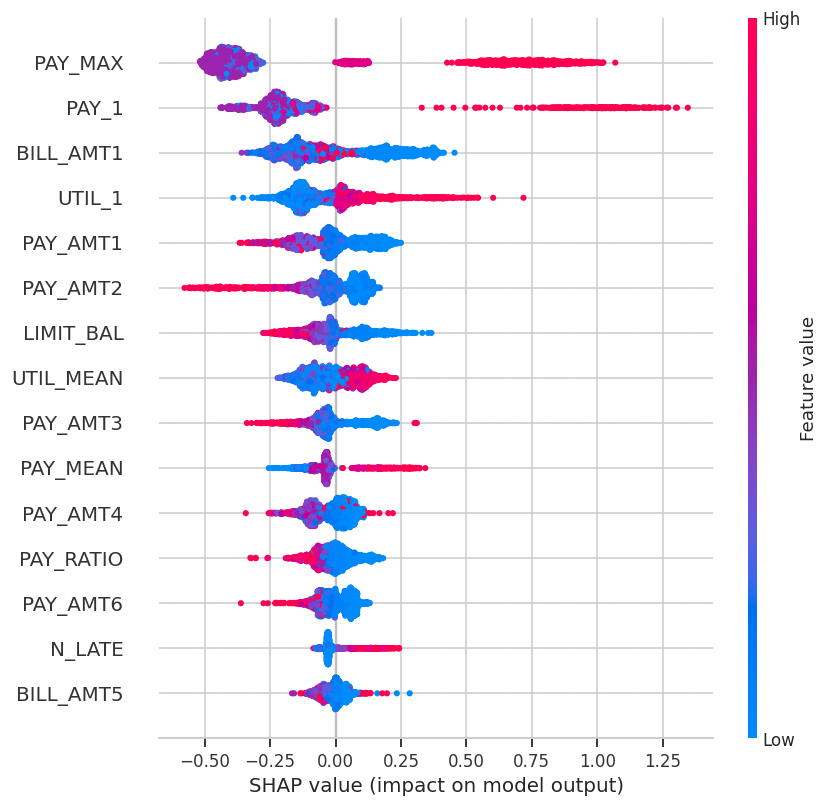

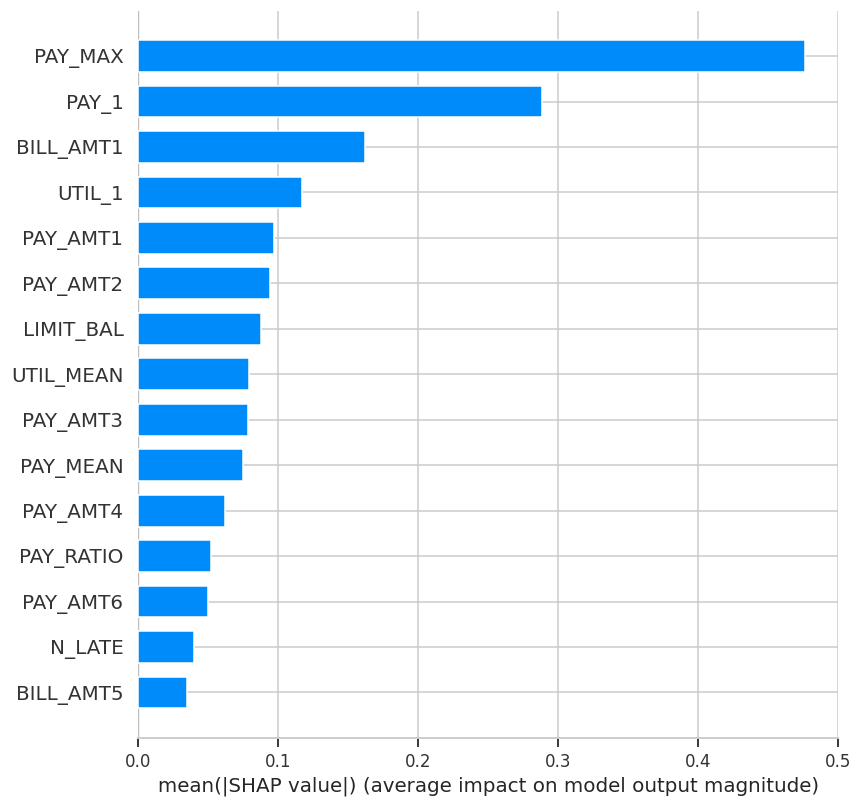

In [19]:
# @title
# ============ 5.5 INTERPRETASI (SHAP) ============
import shap

prep = best_model.named_steps["prep"]
clf = best_model.named_steps["clf"]
names = [n.split("__")[-1] for n in prep.get_feature_names_out()]

sample = X_test.sample(2000, random_state=SEED)
Xt = prep.transform(sample)
if hasattr(Xt, "toarray"):
    Xt = Xt.toarray()

explainer = shap.TreeExplainer(clf)
sv = explainer.shap_values(Xt)

plt.figure()
shap.summary_plot(sv, Xt, feature_names=names, max_display=15, show=False)
save_fig("08_shap_summary")

shap.summary_plot(sv, Xt, feature_names=names, plot_type="bar", max_display=15, show=False)
save_fig("09_shap_bar")

### 5.6 Ringkasan Evaluasi
- Pada data test, XGBoost (tuned) terbaik: ROC-AUC 0,7789, PR-AUC 0,5642, KS 0,4270. Dibanding baseline Logistic Regression (ROC-AUC 0,7536; KS 0,3990), selisihnya +0,0253 ROC-AUC dan +0,0280 KS. Dibanding Random Forest (ROC-AUC 0,7739), unggulnya tipis (+0,0050).
- Pada threshold 0,5, Random Forest memiliki Accuracy tertinggi (0,8016) tetapi Recall terendah (0,5090), sehingga Accuracy menyesatkan untuk data tidak seimbang. XGBoost (tuned) mencapai Recall 0,6297.
- Dampak threshold (XGBoost tuned, 0,50 → 0,332): Recall naik dari 0,630 ke 0,835, Precision turun dari 0,457 ke 0,323, F1 turun dari 0,529 ke 0,466. Default yang lolos (False Negative) turun dari 491 ke 219, sedangkan nasabah lancar yang ditandai berisiko (False Positive) naik dari 993 ke 2.319.
- Kalibrasi probabilitas (bagian 5.4): model dilatih dengan class weighting sehingga probabilitas mentahnya condong terlalu tinggi. Kalibrasi memperbaiki Brier score, Log loss, dan ECE tanpa mengubah urutan nasabah secara berarti (ROC-AUC hampir sama). Threshold 0,332 di atas berlaku pada skala sebelum kalibrasi; pada skala terkalibrasi threshold dihitung ulang dengan cara yang sama (nilainya tercetak di 5.4), dan Recall/Precision-nya dibandingkan di tabel 5.4.
- Menurut SHAP, fitur paling berpengaruh adalah PAY_MAX (rata-rata |SHAP| ≈ 0,48), PAY_1 (≈ 0,29), BILL_AMT1 (≈ 0,16), dan UTIL_1 (≈ 0,12). Nilai PAY_MAX dan PAY_1 yang tinggi (keterlambatan lebih parah) mendorong prediksi ke arah default, sejalan dengan temuan EDA bahwa PAY_1 paling berkorelasi dengan default. Nilai LIMIT_BAL dan PAY_AMT yang tinggi menurunkan risiko, juga sejalan dengan korelasi negatifnya di EDA.
- Catatan interpretasi: N_LATE punya korelasi tertinggi di EDA (r = 0,398) tetapi kontribusi SHAP-nya kecil (≈ 0,04), kemungkinan karena informasinya tumpang tindih dengan PAY_MAX dan PAY_1. Arah BILL_AMT1 juga tidak intuitif (tagihan rendah cenderung menaikkan risiko), kemungkinan karena berkorelasi dengan UTIL_1 dan LIMIT_BAL. SHAP menjelaskan perilaku model, bukan hubungan sebab-akibat.
- Keterbatasan: dataset Taiwan 2005, kode PAY_ -2/0 tidak terdokumentasi, belum ada uji fairness, dan evaluasi (termasuk kalibrasi) memakai satu kali split.

## 6. Deployment
Model terbaik (XGBoost yang sudah dikalibrasi probabilitasnya) disimpan bersama threshold terkalibrasi dan daftar fitur ke satu file `joblib`. Fungsi `predict_applicant()` menerima data mentah calon peminjam, melakukan validasi input, menerapkan preprocessing yang sama seperti saat training, lalu mengembalikan probabilitas default terkalibrasi, skor kredit (300–850), kategori risiko, dan rekomendasi keputusan. Antarmuka demo dibuat dengan Gradio dan dirancang untuk pengguna awam: istilah teknis diganti bahasa sehari-hari, setiap menu dan tabel disertai penjelasan, serta hasil prediksi dilengkapi alasan di baliknya (SHAP).

In [20]:
# @title
# ============ 6.1 SIMPAN MODEL & FUNGSI PREDIKSI ============
import joblib

artifact = {
    "model": calibrated_model,          # XGBoost tuned + kalibrasi probabilitas (5.4)
    "threshold": float(best_thr_cal),   # threshold pada skala probabilitas TERKALIBRASI
    "feature_names": list(X.columns),
    "model_name": BEST_NAME,
    "calibration": CAL_METHOD,
    "raw_threshold": float(best_thr),   # threshold skala lama (tanpa kalibrasi), untuk arsip
}
joblib.dump(artifact, "models/credit_scoring_model.joblib")
print("Model tersimpan di models/credit_scoring_model.joblib")

def predict_applicant(data: dict) -> dict:
    """Input: dict 23 fitur mentah (sama dengan kolom dataset asli)."""
    missing = [c for c in COLS if c not in data or data[c] is None]
    if missing:
        raise ValueError(f"Input belum lengkap: {missing}")

    row = pd.DataFrame([{c: float(data[c]) for c in COLS}])

    # --- validasi input ---
    if row.loc[0, "LIMIT_BAL"] <= 0:
        raise ValueError("LIMIT_BAL harus lebih dari 0")
    if not 18 <= row.loc[0, "AGE"] <= 100:
        raise ValueError("AGE harus antara 18 dan 100")
    if row.loc[0, "SEX"] not in (1, 2):
        raise ValueError("SEX harus 1 atau 2")
    for c in PAY_COLS:
        if not -2 <= row.loc[0, c] <= 9:
            raise ValueError(f"{c} harus antara -2 dan 9")
    for c in AMT_COLS:
        if row.loc[0, c] < 0:
            raise ValueError(f"{c} tidak boleh negatif")

    # --- preprocessing sama seperti training ---
    row["EDUCATION"] = row["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
    row["MARRIAGE"] = row["MARRIAGE"].replace({0: 3})
    row = row.astype({c: int for c in ["SEX", "EDUCATION", "MARRIAGE"] + PAY_COLS})
    row = add_features(row)[artifact["feature_names"]]

    p = float(artifact["model"].predict_proba(row)[0, 1])   # probabilitas terkalibrasi
    thr = artifact["threshold"]

    if p >= thr:
        risk, decision = "Tinggi", "Tolak / tinjau manual"
    elif p >= thr / 2:
        risk, decision = "Sedang", "Setujui dengan limit/bunga disesuaikan"
    else:
        risk, decision = "Rendah", "Setujui"

    return {
        "prob_default": p,
        "score": int(round(300 + (1 - p) * 550)),
        "risk": risk,
        "decision": decision,
    }

Model tersimpan di models/credit_scoring_model.joblib


In [21]:
# @title
# ============ 6.2 UJI FUNGSI PREDIKSI ============
# ambil 3 sampel dari data test, kembalikan ke format data mentah
sample_rows = df_clean.loc[X_test.index[:3], COLS]

for i, (_, r) in enumerate(sample_rows.iterrows()):
    out = predict_applicant(r.to_dict())
    actual = y_test.iloc[i]
    print(f"Sampel {i+1} | aktual={actual} | P(default)={out['prob_default']:.3f} | "
          f"skor={out['score']} | risiko={out['risk']} | {out['decision']}")

# uji penanganan error
try:
    bad = sample_rows.iloc[0].to_dict()
    bad["AGE"] = 5
    predict_applicant(bad)
except ValueError as e:
    print("\nValidasi bekerja ->", e)

Sampel 1 | aktual=0 | P(default)=0.126 | skor=781 | risiko=Sedang | Setujui dengan limit/bunga disesuaikan
Sampel 2 | aktual=0 | P(default)=0.077 | skor=808 | risiko=Sedang | Setujui dengan limit/bunga disesuaikan
Sampel 3 | aktual=0 | P(default)=0.151 | skor=767 | risiko=Tinggi | Tolak / tinjau manual

Validasi bekerja -> AGE harus antara 18 dan 100


In [22]:
# @title 6.3 Demo Gradio (antarmuka untuk pengguna awam)
import re, inspect
import gradio as gr
import shap
from sklearn.metrics import confusion_matrix

# ============ 1. KAMUS: kode teknis -> bahasa awam ============
SEX_CHOICES = [("Pria", 1), ("Wanita", 2)]
EDU_CHOICES = [("Pascasarjana (S2/S3)", 1), ("Universitas (S1/D3/D4)", 2), ("SMA/sederajat", 3), ("Lainnya", 4)]
MAR_CHOICES = [("Menikah", 1), ("Lajang", 2), ("Lainnya", 3)]
CAT_CHOICES = {"SEX": SEX_CHOICES, "EDUCATION": EDU_CHOICES, "MARRIAGE": MAR_CHOICES}

PAY_STATUS_CHOICES = (
    [("Tidak ada tagihan / kartu tidak dipakai (kode -2)*", -2),
     ("Lunas, bayar tepat waktu (kode -1)", -1),
     ("Bayar sebagian / cicilan minimum (kode 0)*", 0)]
    + [(f"Telat {n} bulan", n) for n in range(1, 9)]
    + [("Telat 9 bulan atau lebih", 9)]
)
PAY_SHORT = {-2: "tidak ada tagihan", -1: "lunas tepat waktu", 0: "bayar sebagian/minimum"}
PAY_SHORT.update({n: f"telat {n} bulan" for n in range(1, 10)})

MONTH_LABEL = {1: "Bulan ke-1 (paling baru)", 2: "Bulan ke-2", 3: "Bulan ke-3",
               4: "Bulan ke-4", 5: "Bulan ke-5", 6: "Bulan ke-6 (paling lama)"}

FRIENDLY = {
    "LIMIT_BAL": "Limit kartu kredit", "AGE": "Usia", "SEX": "Jenis kelamin",
    "EDUCATION": "Pendidikan", "MARRIAGE": "Status pernikahan",
    "PAY_MEAN": "Rata-rata status pembayaran 6 bulan",
    "PAY_MAX": "Keterlambatan terparah dalam 6 bulan",
    "N_LATE": "Jumlah bulan terlambat",
    "UTIL_1": "Pemakaian limit bulan terbaru",
    "UTIL_MEAN": "Rata-rata pemakaian limit",
    "PAY_RATIO": "Rasio pembayaran terhadap tagihan",
}
for k in range(1, 7):
    FRIENDLY[f"PAY_{k}"] = f"Status pembayaran bulan ke-{k}"
    FRIENDLY[f"BILL_AMT{k}"] = f"Tagihan bulan ke-{k}"
    FRIENDLY[f"PAY_AMT{k}"] = f"Jumlah dibayar bulan ke-{k}"

# ---------- format angka gaya Indonesia (1.234 dan 12,5%) ----------
def fmt_int(n):
    return f"{int(round(n)):,}".replace(",", ".")

def dec(x, d=3):
    return f"{x:.{d}f}".replace(".", ",")

def pct(x, d=1):
    return f"{x * 100:.{d}f}%".replace(".", ",")

def friendly_feature(name):
    """Nama fitur model -> kalimat awam (termasuk hasil one-hot seperti SEX_1)."""
    if name in FRIENDLY:
        return FRIENDLY[name]
    m = re.match(r"(SEX|EDUCATION|MARRIAGE)_(\d+)", name)
    if m:
        labels = {v: l for l, v in CAT_CHOICES[m.group(1)]}
        return f"{FRIENDLY[m.group(1)]}: {labels.get(int(m.group(2)), m.group(2))}"
    return name

def friendly_msg(msg):
    """Ganti kode kolom pada pesan error dengan nama yang mudah dipahami."""
    for key in sorted(FRIENDLY, key=len, reverse=True):
        msg = msg.replace(key, FRIENDLY[key])
    return msg

def value_text(name, row):
    """Nilai input nasabah untuk sebuah faktor, ditulis dengan bahasa awam (None = tidak ditampilkan)."""
    if name not in row.columns:
        return None
    v = float(row[name].iloc[0])
    if name in PAY_COLS or name == "PAY_MAX":
        return PAY_SHORT.get(int(v))
    if name == "N_LATE":
        return f"{int(v)} bulan"
    if name in ("UTIL_1", "UTIL_MEAN", "PAY_RATIO"):
        return pct(v, 0)
    if name == "AGE":
        return f"{int(v)} tahun"
    if name == "LIMIT_BAL" or name in BILL_COLS or name in AMT_COLS:
        return f"NT$ {fmt_int(v)}"
    return None

# ============ 2. PENJELAS PER NASABAH (SHAP) ============
# Dihitung ulang di sini agar sel ini mandiri.
_prep = best_model.named_steps["prep"]
_clf = best_model.named_steps["clf"]
_feat_names = [n.split("__")[-1] for n in _prep.get_feature_names_out()]
_explainer = shap.TreeExplainer(_clf)

def to_model_row(data):
    """Langkah preprocessing yang sama dengan predict_applicant()."""
    row = pd.DataFrame([{c: float(data[c]) for c in COLS}])
    row["EDUCATION"] = row["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
    row["MARRIAGE"] = row["MARRIAGE"].replace({0: 3})
    row = row.astype({c: int for c in ["SEX", "EDUCATION", "MARRIAGE"] + PAY_COLS})
    return add_features(row)[artifact["feature_names"]]

def top_factors(data, k=3):
    row = to_model_row(data)
    Xt = _prep.transform(row)
    if hasattr(Xt, "toarray"):
        Xt = Xt.toarray()
    sv = _explainer.shap_values(Xt)
    if isinstance(sv, list):
        sv = sv[-1]
    sv = np.asarray(sv)[0]
    order = np.argsort(sv)
    def pack(i):
        return (friendly_feature(_feat_names[i]), value_text(_feat_names[i], row), float(sv[i]))
    up = [pack(i) for i in order[::-1] if sv[i] > 0][:k]
    down = [pack(i) for i in order if sv[i] < 0][:k]
    return up, down

# ============ 3. TAMPILAN HASIL ============
GREEN, AMBER, RED = "#2e9e5b", "#e0a100", "#d64545"
RISK_COLOR = {"Rendah": GREEN, "Sedang": AMBER, "Tinggi": RED}
BORDER = "var(--border-color-primary,#ddd)"
CARD = (f"border:1px solid {BORDER};border-radius:14px;padding:18px;"
        "background:var(--block-background-fill,#fff);color:var(--body-text-color,#222);")
MUTED = "opacity:.75;font-size:13px;"

def risk_explanation(risk, thr):
    return {
        "Rendah": f"Perkiraan peluang gagal bayar di bawah {pct(thr / 2)}. Profil ini tergolong aman menurut model.",
        "Sedang": f"Perkiraan peluang gagal bayar antara {pct(thr / 2)} dan {pct(thr)}. Perlu kehati-hatian, misalnya limit atau bunga disesuaikan.",
        "Tinggi": f"Perkiraan peluang gagal bayar mencapai {pct(thr)} atau lebih. Model menyarankan pemeriksaan manual sebelum disetujui.",
    }[risk]

def risk_bar(p, thr):
    zones = [(thr / 2 * 100, GREEN), (thr / 2 * 100, AMBER), ((1 - thr) * 100, RED)]
    segs = "".join(f'<div style="width:{w:.2f}%;background:{c}"></div>' for w, c in zones)
    labs = "".join(f'<div style="width:{w:.2f}%;text-align:center;white-space:nowrap">{t}</div>'
                   for (w, _), t in zip(zones, ["Rendah", "Sedang", "Tinggi"]))
    pos = min(max(p, 0), 1) * 100
    ticks = "".join(
        f'<div style="position:absolute;left:{x * 100:.2f}%;transform:translateX(-50%);white-space:nowrap">{pct(x)}</div>'
        for x in (thr / 2, thr))
    return (f'<div style="position:relative;margin:26px 0 4px">'
            f'<div style="display:flex;height:14px;border-radius:7px;overflow:hidden">{segs}</div>'
            f'<div style="position:absolute;left:{pos:.2f}%;top:-19px;transform:translateX(-50%);'
            f'font-size:15px;line-height:1" title="Posisi nasabah ini">▼</div></div>'
            f'<div style="display:flex;font-size:12px;opacity:.85">{labs}</div>'
            f'<div style="position:relative;height:16px;font-size:11px;opacity:.65;margin-top:2px">{ticks}</div>'
            f'<div style="{MUTED}font-size:12px">Tanda ▼ menunjukkan posisi nasabah ini pada skala peluang gagal bayar (0% di kiri, 100% di kanan).</div>')

def factor_column(title, items, color, scale):
    if items:
        body = "".join(
            f'<div style="margin:9px 0"><div style="font-size:14px">{n}'
            + (f' <span style="opacity:.65">(isian Anda: {v})</span>' if v else "")
            + f'</div><div style="height:8px;border-radius:4px;background:{color};width:{max(abs(s) / scale * 100, 6):.0f}%"></div></div>'
            for n, v, s in items)
    else:
        body = '<div style="font-size:14px;opacity:.7;margin-top:9px">Tidak ada faktor yang menonjol.</div>'
    return f'<div style="flex:1;min-width:230px"><b>{title}</b>{body}</div>'

def render_result(r, up, down):
    thr = artifact["threshold"]
    col = RISK_COLOR[r["risk"]]
    scale = max([abs(s) for _, _, s in up + down] + [1e-9])
    return f"""
<div style="{CARD}">
  <div style="display:flex;flex-wrap:wrap;gap:18px;align-items:center">
    <div style="text-align:center;min-width:130px">
      <div style="font-size:48px;font-weight:700;line-height:1">{r['score']}</div>
      <div style="{MUTED}">Skor kredit<br>300 = paling berisiko<br>850 = paling aman</div>
    </div>
    <div style="flex:1;min-width:220px">
      <span style="background:{col};color:#fff;padding:4px 14px;border-radius:999px;font-weight:600">Risiko {r['risk']}</span>
      <div style="margin-top:10px;font-size:15px"><b>Saran:</b> {r['decision']}</div>
      <div style="margin-top:6px;font-size:14px">{risk_explanation(r['risk'], thr)}</div>
    </div>
  </div>
  <div style="margin-top:16px;font-size:14px">Perkiraan peluang gagal bayar bulan depan: <b>{pct(r['prob_default'])}</b></div>
  {risk_bar(r['prob_default'], thr)}
  <hr style="border:none;border-top:1px solid {BORDER};margin:18px 0 12px">
  <div style="font-size:15px;margin-bottom:4px"><b>Mengapa hasilnya begini?</b> Faktor yang paling berpengaruh pada data yang Anda isi:</div>
  <div style="display:flex;flex-wrap:wrap;gap:20px">
    {factor_column('▲ Menaikkan risiko', up, RED, scale)}
    {factor_column('▼ Menurunkan risiko', down, GREEN, scale)}
  </div>
  <div style="{MUTED}margin-top:12px">Panjang batang menunjukkan kekuatan pengaruh relatif. Penjelasan ini menggambarkan cara kerja model, bukan hubungan sebab-akibat.</div>
</div>"""

PLACEHOLDER = (f'<div style="{CARD}text-align:center;{MUTED}">'
               'Hasil akan muncul di sini setelah Anda menekan tombol <b>Hitung risiko</b>.</div>')

# ---------- tabel HTML sederhana (dengan penjelasan saat kursor diarahkan ke judul kolom) ----------
def html_table(headers, rows, tips=None, best_cols=None):
    """headers: list judul; rows: list of list; tips: {judul: penjelasan}; best_cols: kolom yang dicetak tebal di nilai terbaiknya."""
    tips = tips or {}
    th = "".join(
        f'<th style="text-align:left;padding:8px 10px;border-bottom:2px solid {BORDER};white-space:nowrap">'
        + (f'<span title="{tips[h]}" style="border-bottom:1px dotted;cursor:help">{h}</span>' if h in tips else h)
        + "</th>" for h in headers)
    body = ""
    for r in rows:
        tds = ""
        for j, cell in enumerate(r):
            style = f"padding:8px 10px;border-bottom:1px solid {BORDER};"
            if best_cols and j in best_cols and cell == best_cols[j](rows, j):
                style += "font-weight:700;background:rgba(46,158,91,.15);"
            tds += f'<td style="{style}">{cell}</td>'
        body += f"<tr>{tds}</tr>"
    return (f'<div style="overflow-x:auto;color:var(--body-text-color,#222)">'
            f'<table style="border-collapse:collapse;width:100%;font-size:14px"><thead><tr>{th}</tr></thead>'
            f'<tbody>{body}</tbody></table></div>')

def render_confusion(tp, fn, fp, tn):
    def cell(bg, title, n, sub):
        return (f'<td style="padding:14px;border:1px solid {BORDER};background:{bg};text-align:center;min-width:150px">'
                f'<div style="font-weight:600">{title}</div>'
                f'<div style="font-size:28px;font-weight:700;line-height:1.3">{fmt_int(n)}</div>'
                f'<div style="{MUTED}">{sub}</div></td>')
    g, a, r_ = "rgba(46,158,91,.20)", "rgba(224,161,0,.22)", "rgba(214,69,69,.20)"
    head = lambda t: (f'<th style="padding:8px;border:1px solid {BORDER};font-size:13px">{t}</th>')
    side = lambda t: (f'<th style="padding:8px;border:1px solid {BORDER};font-size:13px;text-align:left">{t}</th>')
    return (f'<div style="overflow-x:auto;color:var(--body-text-color,#222)">'
            f'<table style="border-collapse:collapse;width:100%">'
            f'<tr><td></td>{head("Model menandai: BERISIKO")}{head("Model menandai: AMAN")}</tr>'
            f'<tr>{side("Kenyataan: nasabah ini <b>benar-benar gagal bayar</b>")}'
            f'{cell(g, "Terdeteksi", tp, f"{pct(tp / (tp + fn))} dari {fmt_int(tp + fn)} nasabah gagal bayar")}'
            f'{cell(r_, "Terlewat", fn, f"{pct(fn / (tp + fn))} dari {fmt_int(tp + fn)} nasabah gagal bayar")}</tr>'
            f'<tr>{side("Kenyataan: nasabah ini <b>sebenarnya lancar</b>")}'
            f'{cell(a, "Salah tandai", fp, f"{pct(fp / (fp + tn))} dari {fmt_int(fp + tn)} nasabah lancar")}'
            f'{cell(g, "Aman dan benar", tn, f"{pct(tn / (fp + tn))} dari {fmt_int(fp + tn)} nasabah lancar")}</tr>'
            f'</table></div>')

# ============ 4. NILAI AWAL & CONTOH PROFIL ============
INPUT_ORDER = (["LIMIT_BAL", "AGE", "SEX", "EDUCATION", "MARRIAGE"]
               + PAY_COLS + BILL_COLS + AMT_COLS)

_med = df_clean[COLS].median()
P_TYPICAL = {c: int(round(_med[c])) for c in COLS}
P_GOOD = dict(LIMIT_BAL=200000, AGE=40, SEX=2, EDUCATION=2, MARRIAGE=1,
              **{f"PAY_{k}": -1 for k in range(1, 7)},
              **dict(zip(BILL_COLS, [30000, 28000, 25000, 26000, 24000, 22000])),
              **dict(zip(AMT_COLS, [28000, 25000, 26000, 24000, 22000, 20000])))
P_BAD = dict(LIMIT_BAL=50000, AGE=28, SEX=1, EDUCATION=3, MARRIAGE=2,
             **dict(zip(PAY_COLS, [3, 3, 2, 2, 2, 2])),
             **dict(zip(BILL_COLS, [49000, 48500, 47000, 46000, 45000, 44000])),
             **dict(zip(AMT_COLS, [0, 0, 1000, 0, 500, 0])))

def profile_values(p):
    return [p[c] for c in INPUT_ORDER]

# ============ 5. FUNGSI UTAMA ============
def run(*vals):
    data = dict(zip(INPUT_ORDER, vals))
    empty = [friendly_feature(c) for c in INPUT_ORDER if data[c] is None or data[c] == ""]
    if empty:
        raise gr.Error("Masih ada isian yang kosong: " + ", ".join(empty[:6])
                       + (" dan lainnya." if len(empty) > 6 else ".")
                       + " Isi semua kolom, atau tekan salah satu tombol contoh di atas.")
    try:
        r = predict_applicant(data)
    except ValueError as e:
        raise gr.Error(friendly_msg(str(e)))
    up, down = top_factors(data)
    return render_result(r, up, down)

# ============ 6. ISI TAB PANDUAN & AKURASI ============
thr_ = artifact["threshold"]
GUIDE_MD = f"""
### Cara membaca hasil
| Yang tampil | Artinya |
|---|---|
| **Skor kredit (300–850)** | Makin tinggi makin aman. Dihitung dari perkiraan peluang gagal bayar: 300 + (1 − peluang) × 550. Ini skor buatan model ini, bukan skor resmi lembaga mana pun. |
| **Perkiraan peluang gagal bayar** | Seberapa besar kemungkinan nasabah tidak membayar tagihan bulan depan, menurut model. Ini perkiraan, bukan angka pasti. Angkanya sudah dikalibrasi: dari 100 nasabah yang sama-sama diperkirakan 20%, sekitar 20 memang gagal bayar pada data uji. Tetap saja ini perkiraan, dan akurasinya terbatas oleh data latih (Taiwan, 2005). |
| **Kategori risiko** | **Rendah**: peluang di bawah {pct(thr_ / 2)}. **Sedang**: {pct(thr_ / 2)} sampai {pct(thr_)}. **Tinggi**: {pct(thr_)} atau lebih. Batas {pct(thr_)} sengaja dipasang rendah, dipilih dari data latih agar sebanyak mungkin nasabah gagal bayar terdeteksi. Jadi kategori *Tinggi* artinya \"layak diperiksa ulang\", bukan \"pasti gagal bayar\". |
| **Saran** | Rekomendasi otomatis: *Setujui*, *Setujui dengan limit/bunga disesuaikan*, atau *Tolak / tinjau manual*. |
| **Mengapa hasilnya begini?** | Tiga faktor yang paling menaikkan dan paling menurunkan risiko pada data yang Anda isi (dihitung dengan metode SHAP). |

### Arti pilihan "Status pembayaran"
| Pilihan di menu | Artinya |
|---|---|
| **Lunas, bayar tepat waktu** | Seluruh tagihan bulan itu dibayar penuh sebelum jatuh tempo. |
| **Bayar sebagian / cicilan minimum*** | Nasabah membayar, tetapi hanya sebagian atau sebatas cicilan minimum. Tagihan yang tersisa menjadi utang berbunga. |
| **Tidak ada tagihan / kartu tidak dipakai*** | Tidak ada transaksi atau tagihan pada bulan itu, sehingga tidak ada yang perlu dibayar. |
| **Telat 1 … 9 bulan** | Pembayaran terlambat sekian bulan dari jatuh tempo. Makin besar angkanya, makin parah. |

### Arti istilah
| Istilah | Artinya |
|---|---|
| **Kalibrasi** | Penyesuaian angka peluang supaya cocok dengan kenyataan. Tanpa kalibrasi, model yang dibuat waspada cenderung memberi peluang gagal bayar yang terlalu besar. |
| **Gagal bayar (default)** | Nasabah tidak membayar tagihan kartu kredit pada bulan berikutnya. |
| **Limit kartu kredit** | Batas maksimum belanja yang diberikan bank. |
| **NT$** | Dolar Taiwan Baru. Data berasal dari bank di Taiwan (2005), jadi semua nominal dalam NT$, bukan Rupiah. |
| **Tagihan** | Total yang harus dibayar nasabah pada bulan itu. |
| **Jumlah dibayar** | Uang yang benar-benar dibayarkan nasabah pada bulan itu. |
| **Status pembayaran** | Apakah nasabah membayar tepat waktu atau telat, dan telat berapa bulan. |
| **Pemakaian limit** | Tagihan dibagi limit. Makin mendekati 100%, makin "penuh" kartunya. |
| **Rasio pembayaran terhadap tagihan** | Total uang yang dibayar dibandingkan total tagihan selama 6 bulan. 100% berarti tagihan dibayar sebanding. |
| **Bulan ke-1 … ke-6** | Bulan ke-1 adalah yang paling baru. Pada data asli, enam bulan ini adalah April–September 2005. |

\\* Arti kode **-2** dan **0** pada status pembayaran tidak dijelaskan di dokumentasi dataset. Penjelasan di menu adalah tafsiran yang umum dipakai.

### Perlu diingat
- Ini alat demo untuk tugas kuliah, bukan sistem persetujuan kredit yang sebenarnya.
- Model dilatih dari data nasabah di Taiwan tahun 2005 sehingga belum tentu cocok untuk kondisi lain.
- Kewajaran model antar kelompok (jenis kelamin, pendidikan, status pernikahan) belum diuji.
"""

MODEL_MD = """
### Tiga model yang dibandingkan
"Model" adalah program yang belajar dari data nasabah lama untuk menebak nasabah baru. Ketiganya diberi data yang sama.

| Model | Cara kerjanya, secara sederhana |
|---|---|
| **Logistic Regression** | Rumus hitung sederhana yang memberi bobot pada tiap faktor. Mudah dijelaskan, dipakai sebagai pembanding dasar. |
| **Random Forest** | Gabungan ratusan "pohon keputusan" (rangkaian pertanyaan ya/tidak) yang saling memberi suara. |
| **XGBoost (tuned)** | Pohon-pohon keputusan yang dibuat bergantian, tiap pohon memperbaiki kesalahan pohon sebelumnya. "Tuned" berarti pengaturannya sudah disetel agar lebih akurat. |
"""

METRIC_MD = """
### Cara membaca ukuran akurasi
Untuk semua ukuran di bawah ini, **angka lebih besar berarti lebih baik**. Skalanya 0 sampai 1.

| Ukuran | Cara membacanya |
|---|---|
| **ROC-AUC** | Kemampuan model membedakan nasabah gagal bayar dari yang lancar. 0,5 = setara menebak acak, 1 = sempurna. |
| **PR-AUC** | Mirip ROC-AUC, tetapi lebih menyoroti kelompok gagal bayar yang jumlahnya lebih sedikit. |
| **KS** | Seberapa jauh model memisahkan dua kelompok nasabah. Ukuran umum di credit scoring. |
| **Accuracy** | Persentase tebakan yang benar secara keseluruhan. Bisa menyesatkan karena sekitar 78% nasabah memang lancar. |
| **Precision** | Dari nasabah yang ditandai berisiko, berapa persen yang benar-benar gagal bayar. |
| **Recall** | Dari semua nasabah yang benar-benar gagal bayar, berapa persen yang berhasil terdeteksi. |
| **F1** | Nilai gabungan Precision dan Recall. |
"""

METRIC_TIPS = {
    "ROC-AUC": "Kemampuan membedakan nasabah gagal bayar dari yang lancar (0,5 = menebak acak, 1 = sempurna)",
    "PR-AUC": "Seperti ROC-AUC, tetapi lebih menyoroti kelompok gagal bayar yang jumlahnya sedikit",
    "KS": "Seberapa jauh model memisahkan dua kelompok nasabah",
    "Accuracy": "Persentase tebakan benar secara keseluruhan (bisa menyesatkan)",
    "Precision": "Dari yang ditandai berisiko, berapa persen yang benar-benar gagal bayar",
    "Recall": "Dari semua yang benar-benar gagal bayar, berapa persen yang terdeteksi",
    "F1": "Gabungan Precision dan Recall",
}

_cols = list(results.columns)
_rows = [[name] + [dec(float(results.loc[name, c]), 3) for c in _cols] for name in results.index]
_best = lambda rows, j: max((r[j] for r in rows), key=lambda s: float(s.replace(",", ".")))
RESULT_HTML = html_table(["Model"] + _cols, _rows, tips=METRIC_TIPS,
                         best_cols={j: _best for j in range(1, len(_cols) + 1)})

_tn, _fp, _fn, _tp = confusion_matrix(
    y_test, (p_test_cal >= artifact["threshold"]).astype(int)).ravel()
CONF_HTML = render_confusion(int(_tp), int(_fn), int(_fp), int(_tn))

ACC_INTRO = (
    f"Model yang dipakai di tab Simulasi: **{BEST_NAME}**. Semua angka di tab ini dihitung dari "
    f"**{fmt_int(len(y_test))}** nasabah data uji, yaitu nasabah yang sengaja disisihkan dan "
    "tidak dipakai saat model belajar. Jadi ini gambaran kinerja pada nasabah yang belum pernah \"dilihat\" model."
)

CONF_MD = (
    f"### Hasil di data uji dengan batas risiko tinggi {pct(thr_)}\n"
    "Tabel di bawah menghitung nasabah di data uji berdasarkan dua hal: tebakan model (kolom) dan kenyataan (baris).\n\n"
    f"Model mendeteksi **{fmt_int(_tp)}** dari **{fmt_int(_tp + _fn)}** nasabah yang benar-benar gagal bayar ({pct(_tp / (_tp + _fn))}). "
    f"Konsekuensinya, **{fmt_int(_fp)}** nasabah yang sebenarnya lancar ikut ditandai berisiko. "
    "Inilah pertukaran yang dipilih: lebih sedikit gagal bayar yang terlewat, tetapi lebih banyak nasabah baik yang perlu diperiksa ulang."
)

THR_NOTE_MD = (
    f"**Mengapa ada dua batas?** Tabel perbandingan di atas memakai batas standar **0,5** pada ketiga model apa adanya (belum dikalibrasi) supaya dinilai dengan adil. "
    f"Simulasi dan tabel hasil di bawah memakai model XGBoost yang sudah dikalibrasi dengan batas **{dec(thr_, 3)}** (peluang {pct(thr_)}), yang dipilih agar lebih banyak nasabah gagal bayar terdeteksi, "
    "karena nasabah gagal bayar yang lolos merugikan lebih besar daripada nasabah baik yang diperiksa ulang."
)

ABOUT_MD = """
### Tentang proyek ini
**UTS Finansial Teknologi** | Universitas Siber Indonesia | Kelas 13.5A.23

**Anggota kelompok**
- Muhammad Adnan Azwan (13240018)
- Mohammad Panji Satrio (13240019)
- Cecilia Putri Winarno (13240021)
- Rendy Aditya Rahmat (13240015)

**Data:** *Default of Credit Card Clients*, UCI Machine Learning Repository (Yeh & Lien, 2009). Berisi 30.000 pemegang kartu kredit di Taiwan pada 2005.

**Metode:** CRISP-DM. Tiga model dibandingkan, lalu model terbaik dipakai pada demo ini.

**Catatan:** Aplikasi ini hanya simulasi untuk keperluan belajar dan bukan keputusan kredit resmi.
"""

# ============ 7. SUSUN ANTARMUKA ============
THEME = gr.themes.Soft()
_launch_has_ui = "css" in inspect.signature(gr.Blocks.launch).parameters
blocks_kwargs = {} if _launch_has_ui else dict(theme=THEME)
launch_kwargs = dict(theme=THEME) if _launch_has_ui else {}

with gr.Blocks(title="Simulasi Risiko Gagal Bayar Kartu Kredit", **blocks_kwargs) as demo:
    gr.Markdown(
        "# Simulasi Risiko Gagal Bayar Kartu Kredit\n"
        "Alat ini memperkirakan seberapa besar kemungkinan pemegang kartu kredit **gagal membayar tagihan bulan depan**, "
        "berdasarkan profil dan riwayat pembayarannya selama 6 bulan terakhir. "
        "Dibuat untuk tugas kuliah (UTS Finansial Teknologi) dengan data nasabah bank di Taiwan tahun 2005. "
        "**Hasilnya hanya simulasi, bukan keputusan kredit resmi.**\n\n"
        "**Menu di atas:** *1. Simulasi* untuk mencoba menghitung risiko · *2. Panduan & istilah* untuk arti semua istilah · "
        "*3. Seberapa akurat modelnya?* untuk hasil pengujian · *4. Tentang proyek* untuk anggota kelompok dan sumber data."
    )
    with gr.Tabs():
        # ---------- TAB 1 ----------
        with gr.Tab("1. Simulasi"):
            gr.Markdown(
                "**Cara pakai:** (1) isi profil nasabah, (2) isi riwayat 6 bulan terakhir, (3) tekan **Hitung risiko**. "
                "Belum punya data? Tekan salah satu tombol contoh di bawah untuk mengisi otomatis, lalu ubah sesuka Anda. "
                "Bingung dengan sebuah istilah? Buka tab **2. Panduan & istilah**."
            )
            with gr.Row():
                b_typ = gr.Button("Isi dengan nilai tipikal")
                b_good = gr.Button("Contoh: rajin bayar tepat waktu")
                b_bad = gr.Button("Contoh: sering telat bayar")
            gr.Markdown("*Nilai tipikal* = nilai tengah dari seluruh nasabah di data. Tombol contoh hanya mengisi kolom, belum menghitung.")

            gr.Markdown("### A. Profil nasabah\nData diri dan batas kartu kredit nasabah.")
            with gr.Row():
                limit = gr.Number(P_TYPICAL["LIMIT_BAL"], label="Limit kartu kredit (NT$)", precision=0,
                                  info="Batas maksimum belanja dari bank. Contoh: 100000.")
                age = gr.Number(P_TYPICAL["AGE"], label="Usia (tahun)", precision=0,
                                info="Antara 18 dan 100 tahun.")
            with gr.Row():
                sex = gr.Dropdown(SEX_CHOICES, value=P_TYPICAL["SEX"], label="Jenis kelamin")
                edu = gr.Dropdown(EDU_CHOICES, value=P_TYPICAL["EDUCATION"], label="Pendidikan terakhir")
                mar = gr.Dropdown(MAR_CHOICES, value=P_TYPICAL["MARRIAGE"], label="Status pernikahan")

            gr.Markdown(
                "### B. Riwayat 6 bulan terakhir\n"
                "Untuk setiap bulan, isi tiga hal: **status pembayaran** (tepat waktu atau telat), "
                "**tagihan** (yang harus dibayar), dan **jumlah dibayar** (yang benar-benar dibayar). "
                "Bulan ke-1 adalah bulan paling baru. Nominal dalam NT$ (dolar Taiwan, bukan Rupiah).  \n"
                "\\* Arti kode -2 dan 0 tidak dijelaskan di dokumentasi dataset; penjelasan di menu adalah tafsiran umum."
            )
            with gr.Accordion("Bingung memilih status pembayaran? Klik di sini", open=False):
                gr.Markdown(
                    "- **Lunas, bayar tepat waktu**: tagihan bulan itu dibayar penuh sebelum jatuh tempo.\n"
                    "- **Bayar sebagian / cicilan minimum**: dibayar, tetapi tidak penuh.\n"
                    "- **Tidak ada tagihan / kartu tidak dipakai**: tidak ada yang perlu dibayar bulan itu.\n"
                    "- **Telat N bulan**: pembayaran terlambat N bulan. Makin besar N, makin berisiko."
                )
            pay_dd, bill_n, paid_n = [], [], []
            for k in range(1, 7):
                gr.Markdown(f"**{MONTH_LABEL[k]}**")
                with gr.Row():
                    pay_dd.append(gr.Dropdown(PAY_STATUS_CHOICES, value=P_TYPICAL[f"PAY_{k}"],
                                              label=f"Status pembayaran (bulan ke-{k})"))
                    bill_n.append(gr.Number(P_TYPICAL[f"BILL_AMT{k}"], label=f"Tagihan (NT$, bulan ke-{k})", precision=0,
                                            info="Boleh negatif jika nasabah kelebihan bayar." if k == 1 else None))
                    paid_n.append(gr.Number(P_TYPICAL[f"PAY_AMT{k}"], label=f"Jumlah dibayar (NT$, bulan ke-{k})", precision=0,
                                            info="Isi 0 jika tidak membayar." if k == 1 else None))

            all_inputs = [limit, age, sex, edu, mar] + pay_dd + bill_n + paid_n
            go = gr.Button("Hitung risiko", variant="primary", size="lg")
            gr.Markdown("### Hasil\nBagian ini menampilkan skor, tingkat risiko, saran, dan alasan di balik hasilnya.")
            out = gr.HTML(PLACEHOLDER)

            go.click(run, inputs=all_inputs, outputs=out)
            b_typ.click(lambda: profile_values(P_TYPICAL), None, all_inputs)
            b_good.click(lambda: profile_values(P_GOOD), None, all_inputs)
            b_bad.click(lambda: profile_values(P_BAD), None, all_inputs)

        # ---------- TAB 2 ----------
        with gr.Tab("2. Panduan & istilah"):
            gr.Markdown("Tab ini menjelaskan arti setiap bagian hasil dan istilah yang dipakai di aplikasi.")
            gr.Markdown(GUIDE_MD)

        # ---------- TAB 3 ----------
        with gr.Tab("3. Seberapa akurat modelnya?"):
            gr.Markdown("Tab ini menunjukkan hasil pengujian model pada data nasabah yang tidak dipakai saat pelatihan. "
                        "Untuk pengguna awam, cukup baca bagian **Hasil di data uji** di paling bawah.")
            gr.Markdown(ACC_INTRO)
            gr.Markdown(MODEL_MD)
            gr.Markdown("### Perbandingan tiga model (batas keputusan standar 0,5)\n"
                        "Setiap baris adalah satu model, setiap kolom adalah satu ukuran akurasi. "
                        "Angka **tebal berlatar hijau** adalah yang terbaik di kolom itu. "
                        "Arahkan kursor ke judul kolom untuk melihat artinya.")
            gr.HTML(RESULT_HTML)
            gr.Markdown(METRIC_MD)
            gr.Markdown(THR_NOTE_MD)
            gr.Markdown(CONF_MD)
            gr.HTML(CONF_HTML)

        # ---------- TAB 4 ----------
        with gr.Tab("4. Tentang proyek"):
            gr.Markdown(ABOUT_MD)

demo.launch(share=True, **launch_kwargs)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://689288bb825cbc72b8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 7. Kesimpulan
- **Hasil utama:** XGBoost (tuned) menjadi model terbaik pada data test dengan ROC-AUC 0,7789 dan KS 0,4270 (baseline Logistic Regression: 0,7536 dan 0,3990). Pada threshold terpilih 0,332, Recall kelas default mencapai 0,835 dengan Precision 0,323 (pada threshold 0,5: Recall 0,630, Precision 0,457).
- **Faktor risiko dominan:** menurut SHAP, riwayat pembayaran: keterlambatan terparah (PAY_MAX) dan status bulan terakhir (PAY_1), disusul BILL_AMT1 dan rasio utilisasi limit (UTIL_1).
- **Implikasi bisnis:** threshold 0,332 menangkap 1.107 dari 1.326 nasabah default di data test (83,5%); default yang lolos turun dari 491 ke 219. Konsekuensinya, 2.319 dari 4.667 nasabah lancar (49,7%) ikut ditandai berisiko, naik dari 993 (21,3%) pada threshold 0,5. Artinya kerugian akibat default berkurang, tetapi peluang bunga dari nasabah baik yang ditolak atau ditinjau manual bertambah. Pilihan threshold akhir perlu disesuaikan dengan biaya aktual False Negative vs False Positive, yang belum dihitung di notebook ini.
- **Keterbatasan:** data Taiwan 2005 dan satu kali split; kode PAY_ -2 dan 0 tidak terdokumentasi; belum ada uji fairness antar kelompok (SEX, EDUCATION, MARRIAGE); belum ada monitoring drift; kalibrasi probabilitas baru diuji pada satu split (tanpa reliability diagram per kelompok nasabah).
- **Kalibrasi:** probabilitas model dikalibrasi (bagian 5.4) sehingga angka peluang di aplikasi mendekati proporsi default nyata. Threshold di aplikasi memakai skala terkalibrasi (nilai tercetak di 5.4), bukan 0,332 yang berlaku pada skala mentah.
- **Saran lanjutan:** uji pada dataset P2P lending lokal, eksperimen SMOTE, monitoring performa setelah deployment.

## Referensi
- Yeh, I. C., & Lien, C. H. (2009). The comparisons of data mining techniques for the predictive accuracy of probability of default of credit card clients. *Expert Systems with Applications, 36*(2), 2473–2480.
- Dataset: UCI Machine Learning Repository, "Default of Credit Card Clients".
- Library: scikit-learn, XGBoost, SHAP, Gradio, pandas, NumPy, matplotlib, seaborn.

In [23]:
!zip -r hasil.zip models figures
from google.colab import files
files.download("hasil.zip")

  adding: models/ (stored 0%)
  adding: models/credit_scoring_model.joblib (deflated 74%)
  adding: figures/ (stored 0%)
  adding: figures/test_results.csv (deflated 28%)
  adding: figures/calibration_results.csv (deflated 19%)
  adding: figures/06_roc_pr_curves.png (deflated 8%)
  adding: figures/04_numeric_distribution.png (deflated 21%)
  adding: figures/threshold_calibrated.csv (deflated 24%)
  adding: figures/02_default_rate_categorical.png (deflated 25%)
  adding: figures/03_default_rate_pay1.png (deflated 22%)
  adding: figures/07b_kalibrasi.png (deflated 11%)
  adding: figures/09_shap_bar.png (deflated 24%)
  adding: figures/cv_results.csv (deflated 45%)
  adding: figures/05_correlation_heatmap.png (deflated 30%)
  adding: figures/01_target_distribution.png (deflated 19%)
  adding: figures/07_confusion_matrix.png (deflated 17%)
  adding: figures/08_shap_summary.png (deflated 5%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>